# Predicción de suscripción a depósito a plazo (Bank Marketing)

**Tarea:** clasificación binaria.
**Variable objetivo:** `y` (1 = el cliente contrata el depósito, 0 = no).
**Métrica de éxito:** ROC AUC y PR AUC (Average Precision), complementadas con
recall y precision de la clase positiva. Se descarta accuracy por el desbalance (~88/12).
**Relevancia de negocio:** priorizar a qué clientes llamar en una campaña con
presupuesto de contactos limitado.

In [1]:
!pip install ucimlrepo -q

import pandas as pd
from ucimlrepo import fetch_ucirepo

bank = fetch_ucirepo(id=222)   # id 222 = Bank Marketing en UCI

df = pd.concat([bank.data.features, bank.data.targets], axis=1)

print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [2]:
df['y'].value_counts(normalize=True) * 100
df.isnull().sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# ¿Los nulos de poutcome coinciden con los clientes nunca contactados (pdays == -1)?
pd.crosstab(df['poutcome'].isnull(), df['pdays'] == -1)

pdays,False,True
poutcome,,
False,8252,0
True,5,36954


In [4]:
# Convertimos y a 0/1 (se puede ejecutar más de una vez sin problema)
df['y'] = df['y'].isin(['yes', 1]).astype(int)

df['y'].value_counts(normalize=True) * 100

,proportion
y,
0,88.30152
1,11.69848


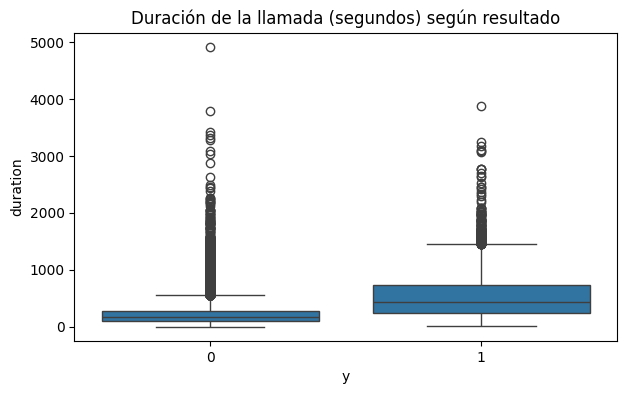

In [5]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='y', y='duration')
plt.title('Duración de la llamada (segundos) según resultado')
plt.show()

In [6]:
df = df.drop(columns=['duration'], errors='ignore')


In [7]:
print('duration' in df.columns)
print(df.shape)

False
(45211, 16)


In [8]:
pd.crosstab(df['poutcome'].isnull(), df['pdays'] == -1)

pdays,False,True
poutcome,,
False,8252,0
True,5,36954


**Hallazgo:** el 99,99% de los nulos de `poutcome` corresponde a clientes con
`pdays == -1` (nunca contactados). El nulo representa "sin campaña previa", no un
dato faltante, por lo que se codifica como una categoría propia en lugar de imputarse.

In [9]:
df['poutcome'] = df['poutcome'].fillna('sin_campana_previa')

In [10]:
df['poutcome'].value_counts()

,count
poutcome,
sin_campana_previa,36959
failure,4901
other,1840
success,1511


In [11]:
df.groupby('contact', dropna=False)['y'].agg(['count', 'mean'])

,count,mean
contact,,
cellular,29285,0.149189
telephone,2906,0.134205
NaN,13020,0.040707


In [12]:
df['contact'] = df['contact'].fillna('desconocido')

In [13]:
df['contact'].value_counts()

,count
contact,
cellular,29285
desconocido,13020
telephone,2906


In [14]:
print(df.groupby('education', dropna=False)['y'].agg(['count', 'mean']))
print(df.groupby('job', dropna=False)['y'].agg(['count', 'mean']))

           count      mean
education                 
primary     6851  0.086265
secondary  23202  0.105594
tertiary   13301  0.150064
NaN         1857  0.135703
               count      mean
job                           
admin.          5171  0.122027
blue-collar     9732  0.072750
entrepreneur    1487  0.082717
housemaid       1240  0.087903
management      9458  0.137556
retired         2264  0.227915
self-employed   1579  0.118429
services        4154  0.088830
student          938  0.286780
technician      7597  0.110570
unemployed      1303  0.155027
NaN              288  0.118056


In [15]:
df['education'] = df['education'].fillna('desconocido')
df['job'] = df['job'].fillna('desconocido')

In [16]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day_of_week,0


In [17]:
numericas = ['age', 'balance', 'campaign', 'pdays', 'previous']
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


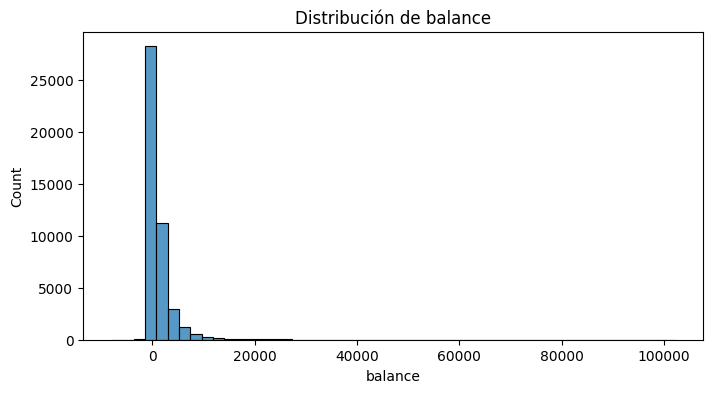

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='balance', bins=50)
plt.title('Distribución de balance')
plt.show()

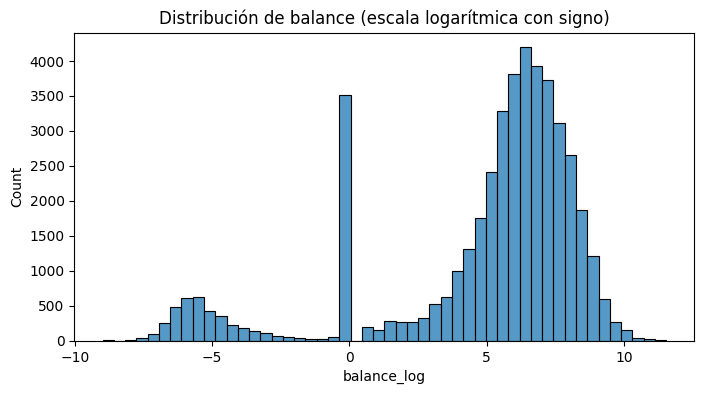

In [19]:
import numpy as np

df['balance_log'] = np.sign(df['balance']) * np.log1p(np.abs(df['balance']))

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='balance_log', bins=50)
plt.title('Distribución de balance (escala logarítmica con signo)')
plt.show()

**Hallazgo:** `balance` presenta fuerte asimetría a la derecha (media 1.362 vs.
mediana 448, máximo 102.127). Se aplicó una transformación logarítmica con signo
(`sign(x) * log1p(|x|)`) que comprime los extremos y conserva los saldos negativos.

In [20]:
print(df['campaign'].value_counts().sort_index().head(10))
print((df['campaign'] > 10).mean() * 100)

campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
Name: count, dtype: int64
2.645373913428148


In [21]:
df['campaign_cap'] = df['campaign'].clip(upper=10)

df[['campaign', 'campaign_cap']].describe().T

,count,mean,std,min,25%,50%,75%,max
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
campaign_cap,45211.0,2.583420,2.133055,1.0,1.0,2.0,3.0,10.0


**Hallazgo:** `campaign` tiene cola larga (máximo 63), pero solo el 2,65% de los
clientes supera los 10 contactos. Se aplicó un tope en 10 (`clip`), ya que
insistir más de 10 veces no difiere en términos de negocio de "contactado en exceso".

In [22]:
print(df['previous'].value_counts().sort_index().head(8))
print((df['previous'] > 5).mean() * 100)
print(((df['previous'] == 0) == (df['pdays'] == -1)).mean() * 100)

previous
0    36954
1     2772
2     2106
3     1142
4      714
5      459
6      277
7      205
Name: count, dtype: int64
2.3534095684678507
100.0


**Hallazgo:** `previous == 0` y `pdays == -1` coinciden en el 100% de los registros
(36.954 clientes, 81,7%): ambas indican "sin contacto previo". Se resume esa
información en una variable binaria y se acota `previous` en 5.

In [23]:
df['contactado_antes'] = (df['previous'] > 0).astype(int)
df['previous_cap'] = df['previous'].clip(upper=5)

df.groupby('contactado_antes')['y'].agg(['count', 'mean'])

,count,mean
contactado_antes,,
0,36954,0.091573
1,8257,0.230713


**Hallazgo:** los clientes con contacto previo (`contactado_antes = 1`) presentan una
tasa de contratación de 23,1%, frente a 9,2% de los nunca contactados (2,5 veces más).

In [24]:
df['pdays_clean'] = df['pdays'].replace(-1, np.nan)

df['pdays_clean'].describe()

,pdays_clean
count,8257.000000
mean,224.577692
std,115.344035
min,1.000000
25%,133.000000
50%,194.000000
75%,327.000000
max,871.000000


**Hallazgo:** en `pdays`, el valor -1 es un código de "sin contacto previo" (81,7% de los
clientes), no una cantidad de días. Se reemplazó por NaN en `pdays_clean`, que queda con
valores reales solo para los 8.257 clientes contactados antes (mediana: 194 días). La
información "contactado / no contactado" se conserva en `contactado_antes`.

In [25]:
print(df.groupby('month')['y'].agg(['count', 'mean']).sort_values('mean', ascending=False))
print(df['day_of_week'].describe())

       count      mean
month                 
mar      477  0.519916
dec      214  0.467290
sep      579  0.464594
oct      738  0.437669
apr     2932  0.196794
feb     2649  0.166478
aug     6247  0.110133
jun     5341  0.102228
nov     3970  0.101511
jan     1403  0.101212
jul     6895  0.090935
may    13766  0.067195
count    45211.000000
mean        15.806419
std          8.322476
min          1.000000
25%          8.000000
50%         16.000000
75%         21.000000
max         31.000000
Name: day_of_week, dtype: float64


**Hallazgo:** `month` muestra gran variación en la tasa de contratación (de 6,7% en mayo
a 52% en marzo), aunque los meses de mayor conversión tienen pocos registros (214 a 738),
por lo que sus tasas son menos estables. `day_of_week` contiene valores de 1 a 31: es el
día del mes, no el día de la semana, por lo que se renombra a `day_of_month`.

In [26]:
df = df.rename(columns={'day_of_week': 'day_of_month'})

df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day_of_month',
 'month',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y',
 'balance_log',
 'campaign_cap',
 'contactado_antes',
 'previous_cap',
 'pdays_clean']

In [27]:
columnas_a_quitar = ['y', 'duration', 'balance', 'campaign', 'previous', 'pdays']

X = df.drop(columns=columnas_a_quitar, errors='ignore')
y = df['y']

print(X.shape)
print(y.shape)
X.dtypes

(45211, 16)
(45211,)


,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
day_of_month,int64
month,object


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(36168, 16) (9043, 16)
0.11698186241981863 0.11699657193409267


In [29]:
assert 'duration' not in X_train.columns, "duration sigue en los datos de entrenamiento"
assert X_train.shape[1] == 16, f"Se esperaban 16 columnas y hay {X_train.shape[1]}"
print("OK: sin duration, 16 columnas")

OK: sin duration, 16 columnas


**Split:** 80% entrenamiento (36.168 filas) / 20% test (9.043 filas), estratificado por
`y` para conservar la proporción de clases (11,7% de "yes" en ambos conjuntos), con
`random_state=42` para garantizar reproducibilidad.

In [30]:
columnas_numericas = X_train.select_dtypes(include='number').columns.tolist()
columnas_categoricas = X_train.select_dtypes(exclude='number').columns.tolist()

print(columnas_numericas)
print(columnas_categoricas)
print(len(columnas_numericas) + len(columnas_categoricas))

['age', 'day_of_month', 'balance_log', 'campaign_cap', 'contactado_antes', 'previous_cap', 'pdays_clean']
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
16


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

prueba = transformador_numerico.fit_transform(X_train[columnas_numericas])

print(np.isnan(prueba).sum())
print(prueba.mean(axis=0).round(2))
print(prueba.std(axis=0).round(2))

0
[-0.  0.  0. -0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1.]


In [32]:
from sklearn.preprocessing import OneHotEncoder

transformador_categorico = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

prueba_cat = transformador_categorico.fit_transform(X_train[columnas_categoricas])

print(prueba_cat.shape)
print(transformador_categorico.get_feature_names_out()[:8])
print(np.unique(prueba_cat))

(36168, 44)
['job_admin.' 'job_blue-collar' 'job_desconocido' 'job_entrepreneur'
 'job_housemaid' 'job_management' 'job_retired' 'job_self-employed']
[0. 1.]


In [33]:
from sklearn.compose import ColumnTransformer

preprocesador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, columnas_numericas),
    ('cat', transformador_categorico, columnas_categoricas)
])

X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)
print(np.isnan(X_train_prep).sum(), np.isnan(X_test_prep).sum())
print(preprocesador.get_feature_names_out()[:10])

(36168, 51) (9043, 51)
0 0
['num__age' 'num__day_of_month' 'num__balance_log' 'num__campaign_cap'
 'num__contactado_antes' 'num__previous_cap' 'num__pdays_clean'
 'cat__job_admin.' 'cat__job_blue-collar' 'cat__job_desconocido']


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

pipe_logit = Pipeline(steps=[
    ('prep', preprocesador),
    ('modelo', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res_logit = cross_validate(
    pipe_logit, X_train, y_train,
    cv=cv,
    scoring=['roc_auc', 'average_precision']
)

print("ROC AUC:", res_logit['test_roc_auc'].mean().round(3), "+/-", res_logit['test_roc_auc'].std().round(3))
print("PR AUC:", res_logit['test_average_precision'].mean().round(3), "+/-", res_logit['test_average_precision'].std().round(3))

ROC AUC: 0.766 +/- 0.004
PR AUC: 0.406 +/- 0.007


**Baseline (Regresión Logística, CV 5 folds):** ROC AUC = 0,766 ± 0,004 y
PR AUC = 0,406 ± 0,007 (piso del PR AUC por azar: 0,117). Cualquier modelo más complejo
debe superar estos valores para justificar su complejidad.

In [35]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline(steps=[
    ('prep', preprocesador),
    ('modelo', RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ))
])

res_rf = cross_validate(
    pipe_rf, X_train, y_train,
    cv=cv,
    scoring=['roc_auc', 'average_precision']
)

print("ROC AUC:", res_rf['test_roc_auc'].mean().round(3), "+/-", res_rf['test_roc_auc'].std().round(3))
print("PR AUC:", res_rf['test_average_precision'].mean().round(3), "+/-", res_rf['test_average_precision'].std().round(3))

ROC AUC: 0.793 +/- 0.005
PR AUC: 0.446 +/- 0.014


**Random Forest (CV 5 folds):** ROC AUC = 0,793 ± 0,005 y PR AUC = 0,446 ± 0,014. Supera
al baseline logístico en +0,027 y +0,040 respectivamente, diferencias mayores a la
variabilidad entre folds, lo que indica que existen relaciones no lineales relevantes.

In [36]:
from xgboost import XGBClassifier

pipe_xgb = Pipeline(steps=[
    ('prep', preprocesador),
    ('modelo', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=42
    ))
])

res_xgb = cross_validate(
    pipe_xgb, X_train, y_train,
    cv=cv,
    scoring=['roc_auc', 'average_precision']
)

print("ROC AUC:", res_xgb['test_roc_auc'].mean().round(3), "+/-", res_xgb['test_roc_auc'].std().round(3))
print("PR AUC:", res_xgb['test_average_precision'].mean().round(3), "+/-", res_xgb['test_average_precision'].std().round(3))

ROC AUC: 0.8 +/- 0.003
PR AUC: 0.452 +/- 0.014


In [37]:
resultados = pd.DataFrame({
    'Regresión Logística': [res_logit['test_roc_auc'].mean(), res_logit['test_average_precision'].mean()],
    'Random Forest': [res_rf['test_roc_auc'].mean(), res_rf['test_average_precision'].mean()],
    'XGBoost': [res_xgb['test_roc_auc'].mean(), res_xgb['test_average_precision'].mean()]
}, index=['ROC AUC', 'PR AUC']).T.round(3)

print(resultados)
print()
print("Diferencia XGBoost - RF por fold (ROC AUC):", (res_xgb['test_roc_auc'] - res_rf['test_roc_auc']).round(3))
print("Diferencia XGBoost - RF por fold (PR AUC): ", (res_xgb['test_average_precision'] - res_rf['test_average_precision']).round(3))

                     ROC AUC  PR AUC
Regresión Logística    0.766   0.406
Random Forest          0.793   0.446
XGBoost                0.800   0.452

Diferencia XGBoost - RF por fold (ROC AUC): [0.003 0.004 0.007 0.008 0.009]
Diferencia XGBoost - RF por fold (PR AUC):  [ 0.002  0.002  0.014  0.01  -0.001]


**Comparación de modelos (CV 5 folds, mismos folds para los tres):**

| Modelo | ROC AUC | PR AUC |
|---|---|---|
| Regresión Logística | 0,766 | 0,406 |
| Random Forest | 0,793 | 0,446 |
| XGBoost | 0,800 | 0,452 |

Los modelos de árboles superan claramente al baseline lineal (+0,03 a +0,04), lo que
indica relaciones no lineales. XGBoost supera a Random Forest en ROC AUC en los 5 folds,
pero por un margen pequeño (~0,006); en PR AUC la diferencia es marginal. Se selecciona
XGBoost para la optimización de hiperparámetros por su rendimiento y su mayor
flexibilidad de ajuste.

In [38]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'modelo__n_estimators': [200, 300, 500],
    'modelo__learning_rate': [0.02, 0.05, 0.1],
    'modelo__max_depth': [3, 4, 5, 6],
    'modelo__min_child_weight': [1, 5, 10],
    'modelo__subsample': [0.7, 0.8, 1.0],
    'modelo__colsample_bytree': [0.6, 0.8, 1.0]
}

busqueda = RandomizedSearchCV(
    estimator=pipe_xgb,
    param_distributions=param_dist,
    n_iter=20,
    scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'},
    refit='pr_auc',
    cv=cv,
    n_jobs=1,
    random_state=42,
    verbose=1
)

busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
print("Mejor PR AUC (CV):", round(busqueda.best_score_, 3))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejores parámetros: {'modelo__subsample': 0.7, 'modelo__n_estimators': 500, 'modelo__min_child_weight': 1, 'modelo__max_depth': 6, 'modelo__learning_rate': 0.02, 'modelo__colsample_bytree': 0.8}
Mejor PR AUC (CV): 0.454


In [39]:
res = pd.DataFrame(busqueda.cv_results_)

cols = ['mean_test_roc_auc', 'mean_test_pr_auc', 'std_test_pr_auc',
        'param_modelo__max_depth', 'param_modelo__learning_rate', 'param_modelo__n_estimators']

print(res[cols].sort_values('mean_test_pr_auc', ascending=False).head(5).round(3))
print()
print("PR AUC de los 20 candidatos: mín =", round(res['mean_test_pr_auc'].min(), 3),
      "| máx =", round(res['mean_test_pr_auc'].max(), 3))

    mean_test_roc_auc  mean_test_pr_auc  std_test_pr_auc  \
15              0.801             0.454            0.013   
1               0.800             0.452            0.013   
5               0.800             0.452            0.014   
2               0.800             0.450            0.014   
7               0.797             0.449            0.015   

    param_modelo__max_depth  param_modelo__learning_rate  \
15                        6                         0.02   
1                         5                         0.02   
5                         6                         0.05   
2                         6                         0.05   
7                         5                         0.10   

    param_modelo__n_estimators  
15                         500  
1                          500  
5                          300  
2                          200  
7                          200  

PR AUC de los 20 candidatos: mín = 0.435 | máx = 0.454


**Optimización (RandomizedSearchCV, 20 combinaciones × 5 folds):** el mejor candidato
(max_depth=6, learning_rate=0,02, n_estimators=500, subsample=0,7, colsample_bytree=0,8,
min_child_weight=1) alcanzó un PR AUC de 0,454 en CV, frente a 0,452 de la configuración
inicial. Los cinco mejores candidatos quedaron dentro de 0,005, menos que la variabilidad
entre folds (~0,014): la optimización aporta una mejora marginal, lo que indica que el
rendimiento está limitado por la información disponible en los datos y no por la
configuración del modelo.

In [40]:
from sklearn.metrics import roc_auc_score, average_precision_score

modelo_final = busqueda.best_estimator_
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print("ROC AUC test:", round(roc_auc_score(y_test, y_proba), 3))
print("PR AUC test:", round(average_precision_score(y_test, y_proba), 3))
print("Piso del PR AUC (azar):", round(y_test.mean(), 3))

ROC AUC test: 0.809
PR AUC test: 0.471
Piso del PR AUC (azar): 0.117


**Evaluación final (conjunto de test, 9.043 clientes, usado una sola vez):**
ROC AUC = 0,809 y PR AUC = 0,471 (piso por azar: 0,117). Los valores son consistentes
con los de validación cruzada (0,801 y 0,454), lo que indica que el modelo no está
sobreajustado y que las estimaciones de CV eran confiables.

In [41]:
resultado = pd.DataFrame({'y_real': y_test.values, 'proba': y_proba})
resultado = resultado.sort_values('proba', ascending=False).reset_index(drop=True)

total_yes = resultado['y_real'].sum()

for pct in [0.10, 0.20, 0.30, 0.50]:
    n = int(len(resultado) * pct)
    capturados = resultado['y_real'].iloc[:n].sum()
    cobertura = capturados / total_yes
    print(f"Llamando al {int(pct*100)}% de clientes mejor rankeados: "
          f"captura {cobertura*100:.1f}% de los 'yes' | lift = {cobertura/pct:.1f}x")

Llamando al 10% de clientes mejor rankeados: captura 45.0% de los 'yes' | lift = 4.5x
Llamando al 20% de clientes mejor rankeados: captura 64.3% de los 'yes' | lift = 3.2x
Llamando al 30% de clientes mejor rankeados: captura 71.7% de los 'yes' | lift = 2.4x
Llamando al 50% de clientes mejor rankeados: captura 83.8% de los 'yes' | lift = 1.7x


**Lectura de negocio (test, 9.043 clientes):** al ordenar a los clientes por probabilidad
de contratación, contactar al 10% mejor rankeado alcanza al 45,0% de los compradores
(lift 4,5x), y contactar al 20% alcanza al 64,3% (lift 3,2x). Los retornos son
decrecientes: pasar del 30% al 50% de clientes suma solo 12 puntos de cobertura. El
punto de corte óptimo depende del costo por contacto y del valor de cada depósito.

**Limitación:** los datos provienen de una campaña pasada en la que la selección de
clientes no fue aleatoria, por lo que los resultados describen el desempeño entre clientes
que efectivamente fueron contactados.

In [42]:
!pip install shap -q

import shap

prep = modelo_final.named_steps['prep']
xgb = modelo_final.named_steps['modelo']

nombres = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
X_test_t = pd.DataFrame(prep.transform(X_test), columns=nombres)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_t)

print(X_test_t.shape)
print(shap_values.shape)

(9043, 51)
(9043, 51)


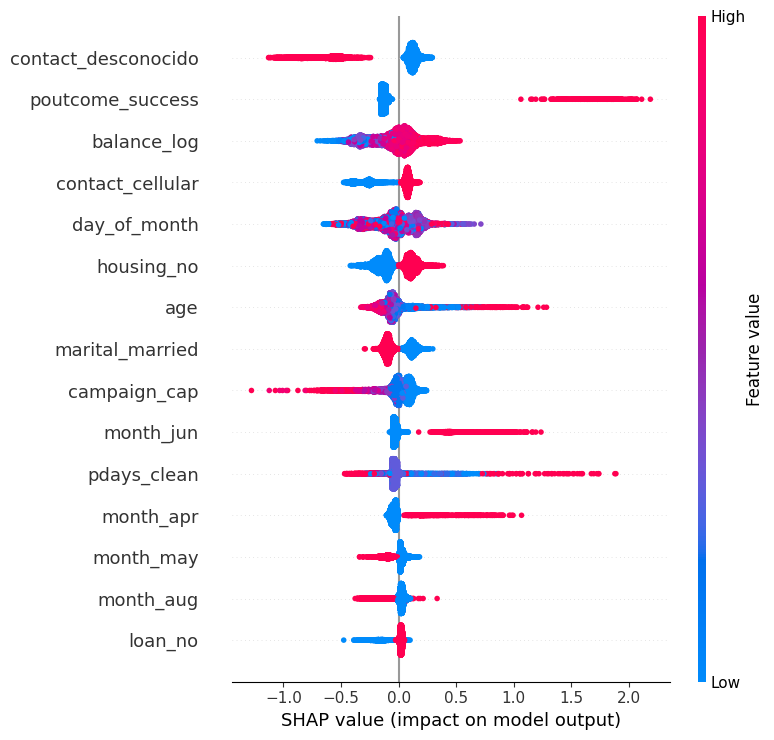

In [43]:
shap.summary_plot(shap_values, X_test_t, max_display=15)

**Explicabilidad (SHAP, conjunto de test):** las variables de mayor influencia fueron
`contact_desconocido` (empuja fuertemente hacia "no"), `poutcome_success` (empuja
fuertemente hacia "sí", aunque afecta a pocos clientes), `balance_log` (mayor saldo,
mayor probabilidad) y `campaign_cap` (más contactos, menor probabilidad). Esto es
consistente con el EDA. Las variables creadas durante la ingeniería de atributos
(`balance_log`, `campaign_cap`) están entre las más influyentes.

**Nota de interpretación:** SHAP describe cómo el modelo usa cada variable, no relaciones
causales; además, variables correlacionadas (p. ej. `poutcome_*` y `contactado_antes`)
se reparten la importancia.

In [44]:
tabla = pd.crosstab(X_train['month'], X_train['contact'], normalize='index') * 100
print(tabla.round(1).loc[['apr', 'may', 'jun', 'aug']])

contact  cellular  desconocido  telephone
month                                    
apr          93.4          0.2        6.3
may          39.0         57.7        3.3
jun          13.8         84.8        1.4
aug          95.2          0.8        4.0


**Hallazgo:** los nulos de `contact` se concentran en mayo (57,7% de las llamadas del
mes) y junio (84,8%), frente a menos del 1% en abril y agosto. La categoría
`desconocido` está así fuertemente asociada al período de la campaña, lo que es
consistente con que SHAP reparta su efecto entre `contact_desconocido` y las variables
de mes. Por esta superposición, `contact_desconocido` no debe interpretarse como un
efecto del canal en sí.

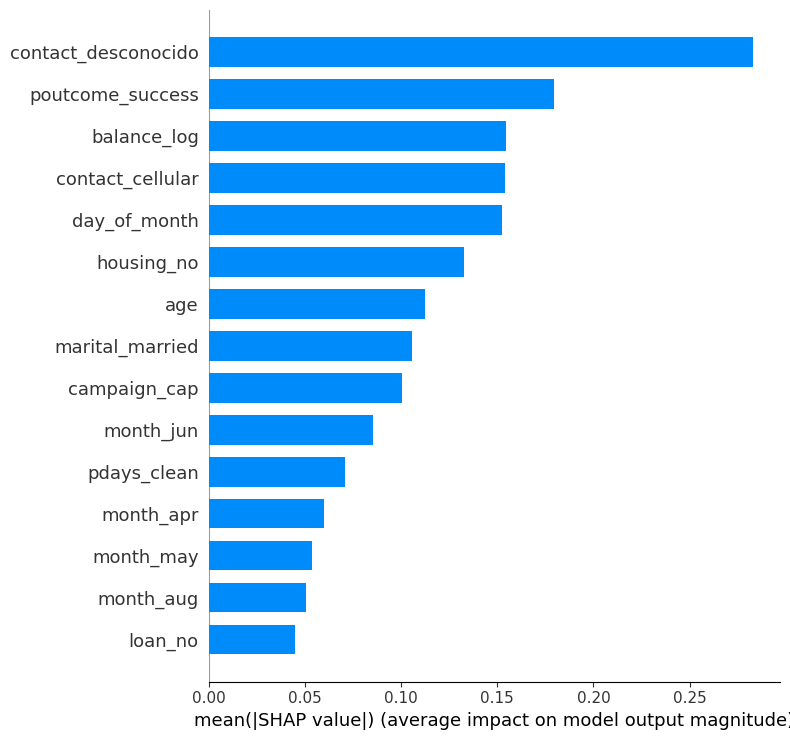

In [45]:
shap.summary_plot(shap_values, X_test_t, plot_type='bar', max_display=15)

**Importancia global (SHAP, media del valor absoluto):** `contact_desconocido` es la
variable de mayor peso (~0,28), seguida de `poutcome_success` (~0,18), `balance_log`,
`contact_cellular` y `day_of_month` (~0,15). Más allá del primer puesto, la importancia
decrece de forma gradual: la capacidad predictiva está distribuida entre muchas variables.

**Limitaciones de interpretación:** (1) el One-Hot Encoding reparte la importancia de una
misma variable entre sus categorías (por ejemplo, `month` aparece en cuatro barras),
por lo que el ranking compara categorías y no variables originales; (2) `day_of_month`
no tiene una interpretación de negocio clara y podría reflejar el calendario de la
campaña, no una característica del cliente.

Probabilidad predicha: 0.929
Resultado real: 1


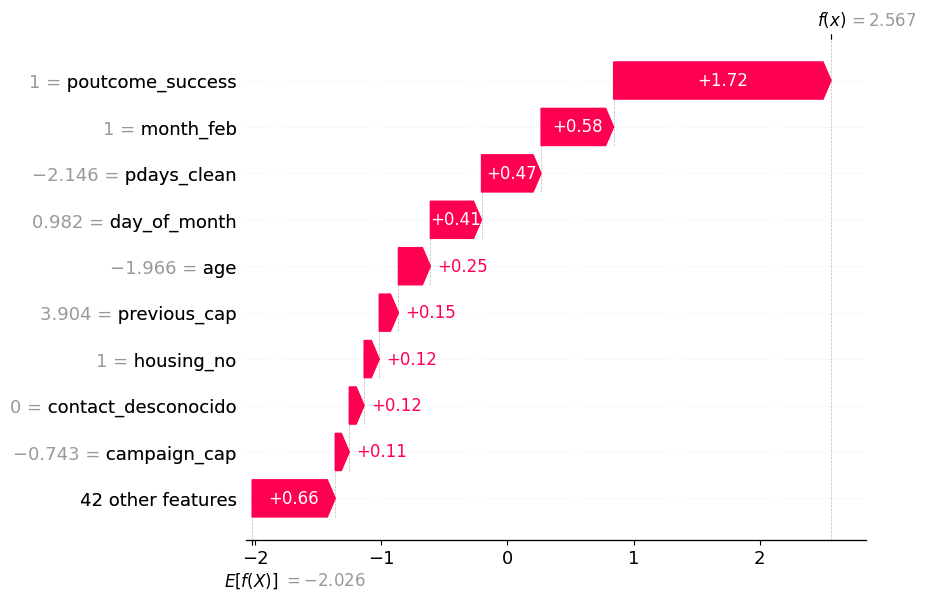

In [46]:
explicacion = explainer(X_test_t)

i = int(np.argmax(y_proba))
print("Probabilidad predicha:", round(float(y_proba[i]), 3))
print("Resultado real:", int(y_test.iloc[i]))

shap.plots.waterfall(explicacion[i], max_display=10)

Probabilidad predicha: 0.007
Resultado real: 0


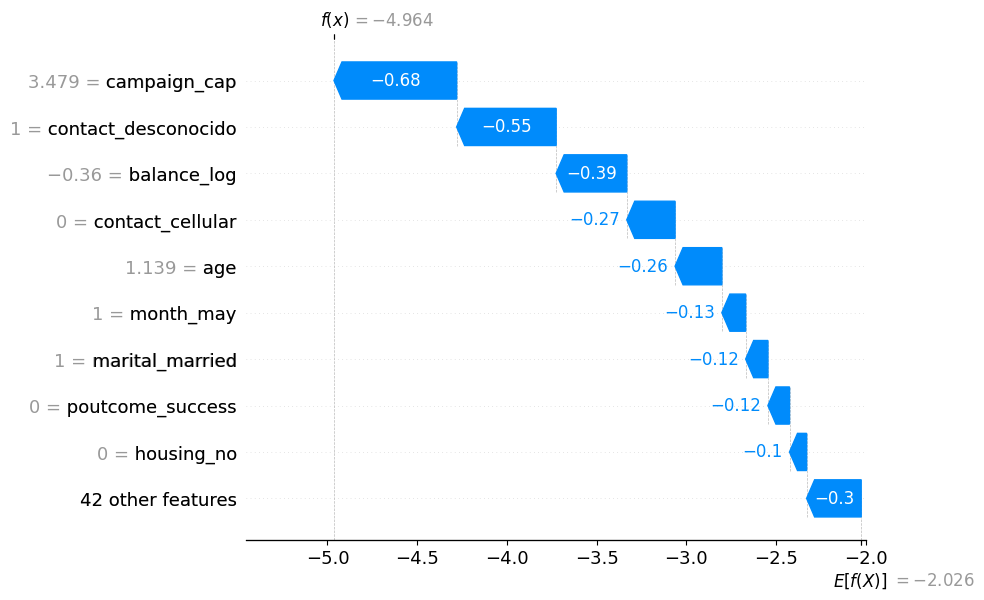

In [47]:
j = int(np.argmin(y_proba))
print("Probabilidad predicha:", round(float(y_proba[j]), 3))
print("Resultado real:", int(y_test.iloc[j]))

shap.plots.waterfall(explicacion[j], max_display=10)

**Explicación individual (cliente con mayor probabilidad, p = 0,929; contrató):** partiendo
de la predicción promedio del modelo (log-odds = -2,03, ≈ 11,6%), el factor dominante fue
`poutcome_success` (+1,72), seguido de `month_feb` (+0,58) y `pdays_clean` (+0,47). Las
diez variables principales empujan en la misma dirección, por lo que es un caso extremo y no
representativo. SHAP descompone aditivamente la predicción: la suma de los empujes más el
valor base reproduce el resultado final del modelo.

**Explicación individual (cliente con menor probabilidad, p = 0,007; no contrató):**
partiendo del valor base (-2,03), el factor dominante fue `campaign_cap` (-0,68; el cliente
fue contactado 10 o más veces), seguido de `contact_desconocido` (-0,55) y `balance_log`
(-0,39). Todas las barras empujan hacia "no". Contrastando ambos casos extremos, el
caso positivo se apoya en una variable muy fuerte (`poutcome_success`, +1,72), mientras
que el negativo resulta de la acumulación de varios empujes moderados.

**Limitación:** ambos ejemplos son casos extremos elegidos para ilustrar el mecanismo de
SHAP; no representan el comportamiento del modelo con clientes de probabilidad intermedia.

In [48]:
from importlib.metadata import version
import sys

print("Python:", sys.version.split()[0])
for paquete in ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'shap', 'matplotlib', 'seaborn', 'ucimlrepo']:
    print(f"{paquete}=={version(paquete)}")

Python: 3.13.16
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.54.1
matplotlib==3.10.0
seaborn==0.13.2
ucimlrepo==0.0.7
